# 5b. Uji sensitivitas: bagaimana kalau terigu dihitung?

Di Notebook 2 aku menulis bahwa terigu (mie) **belum masuk** karena belum ada di PIHPS. Jadi semua angka Notebook 2 sampai 5 adalah **biaya bahan tanpa mie**.

Sekarang datanya ketemu (dari Badan Pangan Nasional). Pertanyaan notebook ini:

**Kalau mienya ikut dihitung, apakah kesimpulan Notebook 2 sampai 5 berubah?**

Ini namanya **analisis sensitivitas**: ubah satu asumsi, lalu lihat apakah hasilnya ikut berubah. Kalau kesimpulan bertahan, hasilnya lebih bisa dipercaya. Kalau berbalik, notebook sebelumnya harus dikerjakan ulang.

## Data terigu dan batasannya

- **Sumber:** Badan Pangan Nasional, *Rata-rata Harga Pangan Bulanan Tingkat Konsumen Nasional (Angka Agustus 2025)*, harga nasional per kg.
- Aku pakai **Tepung Terigu Curah**, satu-satunya yang lengkap sejak Jan 2021 (Kemasan baru ada sejak Apr 2023).
- Datanya berakhir **Agustus 2025**, sedangkan data PIHPS kita sampai Sep 2026. Jadi perbandingan hanya adil di **periode yang sama: Jan 2021 sampai Agu 2025** (56 bulan). Bulan setelah itu tidak kutebak.
- Resep asumsi: **100 g terigu per porsi**.

## Langkah 1: Biaya tanpa terigu (sama seperti Notebook 2 dan 5)

Kodenya sengaja disalin dari notebook sebelumnya supaya angkanya identik. **Cek:** Jan 2021 harus ±Rp 2.763 dan Sep 2026 ±Rp 3.613.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# nama bulan bahasa Indonesia untuk teks (supaya tidak tercampur "Aug", "May")
bln = lambda t: ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'][t.month - 1] + f' {t.year}'

DATA ='/kaggle/input/datasets/samuelgeraldo/bedah-mie-ayam-pakai-data-bukan-sumpit/harga_pangan_bersih.csv'
df = pd.read_csv(DATA)

wide = df.pivot(index='bulan', columns='komoditas', values='harga_rp')
wide.index = pd.to_datetime(wide.index)
wide = wide.interpolate(limit_direction='both')   # isi bulan kosong, sama seperti Notebook 2 dan 5
wide = wide[wide.index < '2026-10-01']             # Okt 2026 belum utuh
wide.shape

(69, 5)

In [2]:
minyak = wide[['Minyak Goreng Kemasan Bermerk 1', 'Minyak Goreng Kemasan Bermerk 2']].mean(axis=1)

biaya = pd.DataFrame({
    'ayam':         wide['Daging Ayam Ras Segar']      * 60 / 1000,
    'bawang_merah': wide['Bawang Merah Ukuran Sedang'] * 10 / 1000,
    'bawang_putih': wide['Bawang Putih Ukuran Sedang'] *  5 / 1000,
    'minyak':       minyak * 20 / 1000,
})
biaya['total'] = biaya.sum(axis=1)
print('Cek Notebook 2: Jan 2021 =', round(biaya['total'].iloc[0]), '| Sep 2026 =', round(biaya['total'].iloc[-1]))

Cek Notebook 2: Jan 2021 = 2763 | Sep 2026 = 3613


## Langkah 2: Muat data terigu

Datanya kecil (56 baris), jadi kutaruh langsung di notebook supaya tidak perlu membuat dataset baru. Satuan: Rp per kg. Kolom `kemasan` kosong sebelum Apr 2023 karena memang belum ada di sumbernya.

In [3]:
from io import StringIO

TERIGU_CSV = """bulan,curah,kemasan
2021-01,8291,
2021-02,8312,
2021-03,8351,
2021-04,8392,
2021-05,8434,
2021-06,8401,
2021-07,8481,
2021-08,8472,
2021-09,8488,
2021-10,8502,
2021-11,8576,
2021-12,8688,
2022-01,8948,
2022-02,9138,
2022-03,9348,
2022-04,9719,
2022-05,9854,
2022-06,9989,
2022-07,10296,
2022-08,10507,
2022-09,10791,
2022-10,10933,
2022-11,11023,
2022-12,11140,
2023-01,11190,
2023-02,11226,
2023-03,11279,
2023-04,11266,13827
2023-05,11216,13811
2023-06,11151,13769
2023-07,11126,13748
2023-08,11107,13769
2023-09,11054,13758
2023-10,11021,13712
2023-11,10972,13689
2023-12,10914,13654
2024-01,10818,13606
2024-02,10781,13655
2024-03,11524,14446
2024-04,11474,14417
2024-05,11090,14383
2024-06,10829,14291
2024-07,10712,14297
2024-08,10337,13469
2024-09,10285,13244
2024-10,10239,13189
2024-11,10216,13192
2024-12,10204,13167
2025-01,9794,12854
2025-02,9789,12900
2025-03,9807,12938
2025-04,9814,12949
2025-05,9811,12974
2025-06,9798,12992
2025-07,9779,12976
2025-08,9792,13036"""

terigu = pd.read_csv(StringIO(TERIGU_CSV))
terigu['bulan'] = pd.to_datetime(terigu['bulan'])
terigu = terigu.set_index('bulan')
print(f"{len(terigu)} bulan: {bln(terigu.index[0])} sampai {bln(terigu.index[-1])}")
print('Bulan kosong di kolom curah:', terigu['curah'].isna().sum())
terigu.tail(3)

56 bulan: Jan 2021 sampai Agu 2025
Bulan kosong di kolom curah: 0


,curah,kemasan
bulan,,
2025-06-01,9798,12992.0
2025-07-01,9779,12976.0
2025-08-01,9792,13036.0


### Seperti apa harga terigu itu sendiri?

Sebelum dimasukkan ke biaya, lihat dulu apakah harganya datar (kalau datar, efeknya mudah ditebak) atau naik-turun.

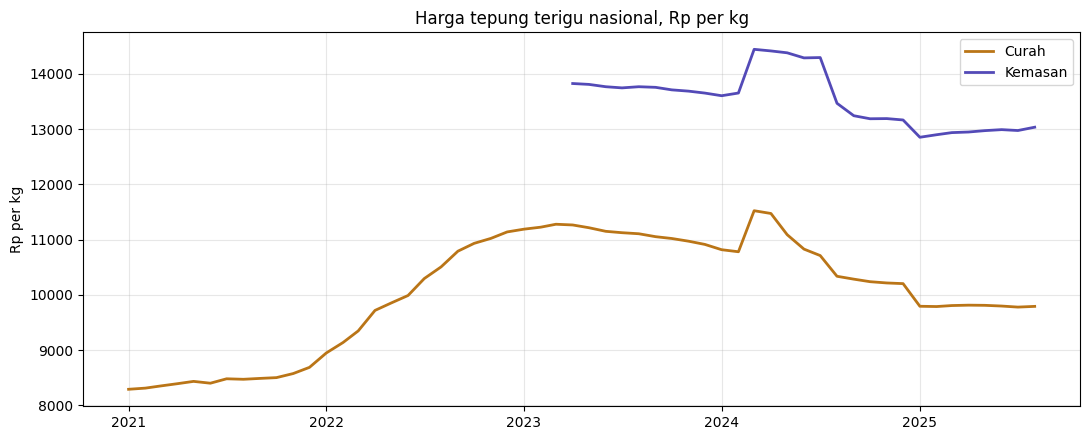

Curah: 8,291 (Jan 2021) -> 9,792 (Agu 2025), puncak 11,524 di Mar 2024


In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(terigu.index, terigu['curah'], color='#BA7517', linewidth=2, label='Curah')
ax.plot(terigu.index, terigu['kemasan'], color='#534AB7', linewidth=2, label='Kemasan')
ax.set_title('Harga tepung terigu nasional, Rp per kg')
ax.set_ylabel('Rp per kg'); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

c = terigu['curah']
print(f"Curah: {c.iloc[0]:,.0f} ({bln(c.index[0])}) -> {c.iloc[-1]:,.0f} ({bln(c.index[-1])}), puncak {c.max():,.0f} di {bln(c.idxmax())}")

Harganya naik-turun selama beberapa tahun, jadi menambahkan terigu bukan sekadar menggeser seluruh angka ke atas. Kemasan lebih mahal daripada Curah (sekitar sepertiga lebih tinggi di Agu 2025).

## Langkah 3: Biaya per porsi dengan terigu

Rumusnya sama seperti bahan lain: harga per kg × gram resep ÷ 1000. Untuk terigu: harga × 100 ÷ 1000.

Kita bangun dua versi di **periode yang sama** (sampai bulan terakhir data terigu): `tanpa` (seperti Notebook 2) dan `dengan` (ditambah terigu).

In [5]:
akhir = terigu.index.max()                          # Agu 2025

tanpa = biaya.loc[:akhir, ['ayam', 'bawang_merah', 'bawang_putih', 'minyak']].copy()
tanpa['total'] = tanpa.sum(axis=1)

dengan = tanpa.drop(columns='total').copy()
dengan['terigu'] = terigu['curah'] * 100 / 1000      # 100 g terigu per porsi
dengan['total'] = dengan.sum(axis=1)

def ringkas(x):
    return pd.Series({
        'awal (Rp/porsi)': x['total'].iloc[0],
        'akhir (Rp/porsi)': x['total'].iloc[-1],
        'naik (%)': 100 * (x['total'].iloc[-1] / x['total'].iloc[0] - 1),
        'porsi ayam di akhir (%)': 100 * x['ayam'].iloc[-1] / x['total'].iloc[-1],
    })

ringkasan = pd.DataFrame({'tanpa terigu': ringkas(tanpa), 'dengan terigu': ringkas(dengan)}).round(1)
puncak = {'tanpa terigu': tanpa['total'].idxmax(), 'dengan terigu': dengan['total'].idxmax()}
porsi_terigu = 100 * dengan['terigu'] / dengan['total']

print('Bulan puncak:', {k: f'{v:%Y-%m}' for k, v in puncak.items()})
print(f"Porsi terigu dari total modal: awal {porsi_terigu.iloc[0]:.1f}%, akhir {porsi_terigu.iloc[-1]:.1f}%, rata-rata {porsi_terigu.mean():.1f}%")
ringkasan

Bulan puncak: {'tanpa terigu': '2021-06', 'dengan terigu': '2024-05'}
Porsi terigu dari total modal: awal 23.1%, akhir 22.6%, rata-rata 24.4%


,tanpa terigu,dengan terigu
awal (Rp/porsi),2763.0,3592.1
akhir (Rp/porsi),3359.2,4338.4
naik (%),21.6,20.8
porsi ayam di akhir (%),64.0,49.6


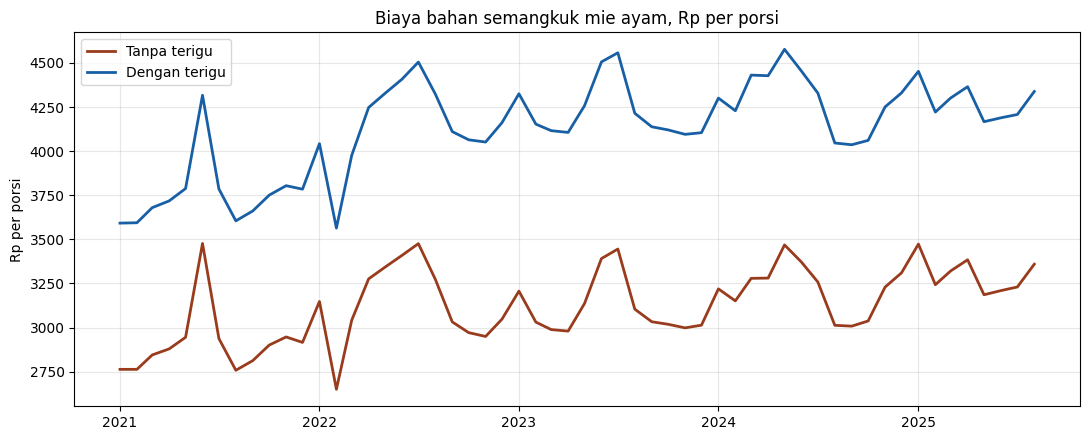

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(tanpa.index, tanpa['total'], color='#993C1D', linewidth=2, label='Tanpa terigu')
ax.plot(dengan.index, dengan['total'], color='#185FA5', linewidth=2, label='Dengan terigu')
ax.set_title('Biaya bahan semangkuk mie ayam, Rp per porsi')
ax.set_ylabel('Rp per porsi'); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## Langkah 4: Ulangi efek Lebaran di dua versi

Metodenya **persis Notebook 5**: hitung % perubahan dari bulan sebelumnya, beri label jarak dari bulan Lebaran (0 = bulan Lebaran, +1 = sebulan sesudah), lalu rata-ratakan per jarak. Bedanya hanya periode: data berhenti di Agu 2025, jadi yang masuk 5 Lebaran (2021 sampai 2025), bukan 6.

In [7]:
lebaran = pd.to_datetime(pd.Series({
    2021: '2021-05-13', 2022: '2022-05-02', 2023: '2023-04-22',
    2024: '2024-04-10', 2025: '2025-03-31', 2026: '2026-03-20',
}))
lebaran_bulan = [d.to_period('M').to_timestamp() for d in lebaran]

def jarak_ke_lebaran(tgl):
    selisih = [(tgl.year - b.year) * 12 + tgl.month - b.month for b in lebaran_bulan]
    return min(selisih, key=abs)

def tahun_lebaran(tgl):
    return min(lebaran_bulan, key=lambda b: abs((tgl.year - b.year) * 12 + tgl.month - b.month)).year

def hitung_perubahan(x):
    p = x.pct_change() * 100
    p = p.drop(pd.Timestamp('2021-02-01')).dropna()    # Jan 2021 hasil isian, jadi perubahan Feb 2021 palsu
    p['jarak'] = [jarak_ke_lebaran(t) for t in p.index]
    p['tahun'] = [tahun_lebaran(t) for t in p.index]
    return p

p_tanpa = hitung_perubahan(tanpa)
p_dengan = hitung_perubahan(dengan)

def efek_per_jarak(p):
    jendela = p[p['jarak'].between(-3, 3)]
    return jendela.groupby('jarak')['total'].mean()

def baseline(p):
    return p[~p['jarak'].between(-3, 3)]['total'].mean()

efek = pd.DataFrame({'tanpa terigu': efek_per_jarak(p_tanpa), 'dengan terigu': efek_per_jarak(p_dengan)}).round(2)
print(f"Rata-rata bulan biasa: tanpa terigu {baseline(p_tanpa):.2f}% | dengan terigu {baseline(p_dengan):.2f}%")
print('Jarak dengan kenaikan terbesar:', efek.idxmax().to_dict())
efek

Rata-rata bulan biasa: tanpa terigu -0.09% | dengan terigu -0.00%
Jarak dengan kenaikan terbesar: {'tanpa terigu': 1, 'dengan terigu': 1}


,tanpa terigu,dengan terigu
jarak,,
-3,-0.32,-0.32
-2,3.01,2.23
-1,0.99,1.32
0,1.29,1.07
1,6.59,4.87
2,-2.82,-2.30
3,-2.59,-1.98


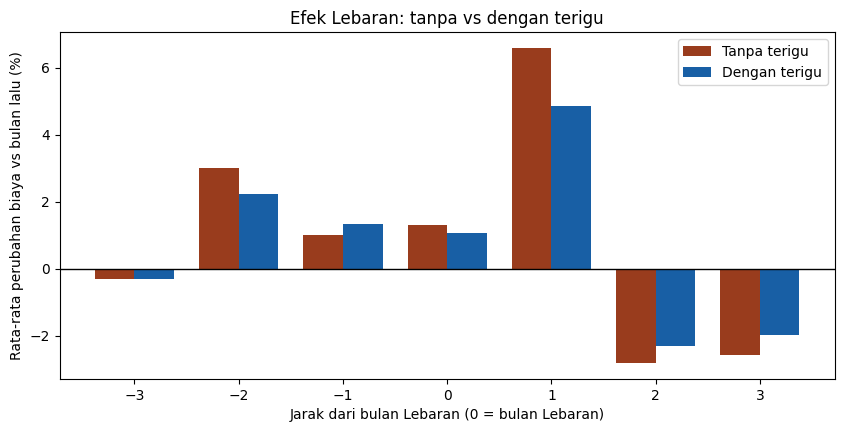

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
lebar = 0.38
x = efek.index.to_numpy()
ax.bar(x - lebar/2, efek['tanpa terigu'], lebar, color='#993C1D', label='Tanpa terigu')
ax.bar(x + lebar/2, efek['dengan terigu'], lebar, color='#185FA5', label='Dengan terigu')
ax.axhline(0, color='black', lw=1)
ax.set_xlabel('Jarak dari bulan Lebaran (0 = bulan Lebaran)')
ax.set_ylabel('Rata-rata perubahan biaya vs bulan lalu (%)')
ax.set_title('Efek Lebaran: tanpa vs dengan terigu')
ax.legend()
plt.show()

## Langkah 5: Cek ketahanan (tanpa 2022)

Di Notebook 5, tahun 2022 menggeser hasil sebelum Lebaran. Kita cek lagi dengan membuang 2022.

In [9]:
def tanpa_2022(p):
    j = p[p['jarak'].between(-3, 3) & (p['tahun'] != 2022)]
    return j.groupby('jarak')['total'].mean()

cek = pd.DataFrame({'tanpa terigu': tanpa_2022(p_tanpa), 'dengan terigu': tanpa_2022(p_dengan)}).round(2)
cek

,tanpa terigu,dengan terigu
jarak,,
-3,4.84,3.53
-2,0.07,-0.11
-1,-0.69,-0.06
0,1.11,0.86
1,7.74,5.63
2,-4.01,-3.43
3,-1.79,-1.47


## Langkah 6: Kenapa kenaikan sesudah Lebaran mengecil?

Lihat perubahan tiap komponen di **jarak +1** (sebulan sesudah Lebaran), per tahun dan rata-ratanya.

In [10]:
t1 = p_dengan[p_dengan['jarak'] == 1][['terigu', 'ayam', 'bawang_merah', 'bawang_putih', 'minyak', 'total']].round(2)
t1.index = t1.index.strftime('%Y-%m')
rata_t1 = t1.mean().round(2)
print('Rata-rata perubahan di jarak +1 (%):', rata_t1.to_dict())
t1

Rata-rata perubahan di jarak +1 (%): {'terigu': -0.55, 'ayam': 4.0, 'bawang_merah': 25.9, 'bawang_putih': 8.59, 'minyak': 1.16, 'total': 4.87}


,terigu,ayam,bawang_merah,bawang_putih,minyak,total
bulan,,,,,,
2021-06,-0.39,16.11,38.54,29.85,3.94,13.96
2022-06,1.37,-0.62,19.94,-3.74,-0.03,1.85
2023-05,-0.44,5.19,10.67,4.98,0.96,3.69
2024-05,-3.35,-0.26,46.02,8.24,-0.12,3.38
2025-04,0.07,-0.40,14.35,3.61,1.04,1.49


Terigu hampir tidak naik di jarak +1 (rata-rata malah sedikit turun). Jadi ia tidak ikut mendorong lonjakan. Ia hanya **memperbesar total modal**, sehingga kenaikan bawang dan ayam jadi persentase yang lebih kecil dari total.

## Satu pembanding: Curah vs Kemasan

Kalau terigunya Kemasan, bukan Curah, porsinya di modal lebih besar. Hanya level yang kita bandingkan di sini, karena Kemasan baru ada sejak Apr 2023.

In [11]:
rp = lambda x: f"Rp {x:,.0f}".replace(',', '.')

k_akhir = terigu['kemasan'].iloc[-1] * 100 / 1000
c_akhir = dengan['terigu'].iloc[-1]
tot_tanpa_akhir = tanpa['total'].iloc[-1]
print(f"Terigu per porsi {bln(akhir)}: Curah {rp(c_akhir)} | Kemasan {rp(k_akhir)}")
print(f"Porsi terigu dari total modal: Curah {100 * c_akhir / (tot_tanpa_akhir + c_akhir):.1f}% | Kemasan {100 * k_akhir / (tot_tanpa_akhir + k_akhir):.1f}%")

Terigu per porsi Agu 2025: Curah Rp 979 | Kemasan Rp 1.304
Porsi terigu dari total modal: Curah 22.6% | Kemasan 28.0%


In [12]:
koma = lambda x: f"{x:.1f}".replace('.', ',')
koma2 = lambda x: f"{x:.2f}".replace('.', ',')

display(Markdown(f"""
## Kesimpulan: apakah terigu mengubah ceritanya?

**Periode perbandingan:** {bln(tanpa.index[0])} sampai {bln(tanpa.index[-1])} ({len(tanpa)} bulan), 100 g terigu Curah per porsi.

- **Terigu itu besar.** Rata-rata sekitar **{koma(porsi_terigu.mean())}%** dari total modal. Modal {bln(tanpa.index[0])} jadi **{rp(ringkasan.loc['awal (Rp/porsi)', 'dengan terigu'])}** per porsi kalau mienya dihitung, bukan **{rp(ringkasan.loc['awal (Rp/porsi)', 'tanpa terigu'])}**. Jadi angka Notebook 2 memang belum lengkap.
- **Tren total hampir sama.** Naik **{koma(ringkasan.loc['naik (%)', 'tanpa terigu'])}%** tanpa terigu dan **{koma(ringkasan.loc['naik (%)', 'dengan terigu'])}%** dengan terigu.
- **Ayam masih bahan terbesar, tapi porsinya mengecil:** dari **{koma(ringkasan.loc['porsi ayam di akhir (%)', 'tanpa terigu'])}%** jadi **{koma(ringkasan.loc['porsi ayam di akhir (%)', 'dengan terigu'])}%** dari total modal.
- **Pola Lebaran bertahan, ukurannya mengecil.** Sebulan sesudah Lebaran biaya naik **{koma(efek.loc[1, 'tanpa terigu'])}%** tanpa terigu dan **{koma(efek.loc[1, 'dengan terigu'])}%** dengan terigu. Bulan berikutnya turun lagi ({koma(efek.loc[2, 'tanpa terigu'])}% dan {koma(efek.loc[2, 'dengan terigu'])}%). Terigu sendiri tidak ikut naik di jarak +1 (rata-rata {koma2(rata_t1['terigu'])}%), jadi ia hanya mengencerkan kenaikan bawang dan ayam.
- **Sebelum Lebaran tetap tidak konsisten.** Tanpa 2022, jarak -2 tinggal {koma2(cek.loc[-2, 'tanpa terigu'])}% (tanpa terigu) dan {koma2(cek.loc[-2, 'dengan terigu'])}% (dengan terigu), hampir nol.
- **Satu hal bergeser: bulan puncak.** Tanpa terigu puncaknya **{bln(puncak['tanpa terigu'])}**, dengan terigu **{bln(puncak['dengan terigu'])}**, karena harga terigu sendiri sedang tinggi saat itu.

**Jadi:** arah kesimpulan Notebook 2 sampai 5 bertahan. Yang berubah adalah ukuran angkanya, sehingga angka di notebook-notebook itu dibaca sebagai **biaya bahan tanpa mie**. Karena kesimpulannya tidak berbalik, notebook-notebook itu tidak kuubah.
"""))


## Kesimpulan: apakah terigu mengubah ceritanya?

**Periode perbandingan:** Jan 2021 sampai Agu 2025 (56 bulan), 100 g terigu Curah per porsi.

- **Terigu itu besar.** Rata-rata sekitar **24,4%** dari total modal. Modal Jan 2021 jadi **Rp 3.592** per porsi kalau mienya dihitung, bukan **Rp 2.763**. Jadi angka Notebook 2 memang belum lengkap.
- **Tren total hampir sama.** Naik **21,6%** tanpa terigu dan **20,8%** dengan terigu.
- **Ayam masih bahan terbesar, tapi porsinya mengecil:** dari **64,0%** jadi **49,6%** dari total modal.
- **Pola Lebaran bertahan, ukurannya mengecil.** Sebulan sesudah Lebaran biaya naik **6,6%** tanpa terigu dan **4,9%** dengan terigu. Bulan berikutnya turun lagi (-2,8% dan -2,3%). Terigu sendiri tidak ikut naik di jarak +1 (rata-rata -0,55%), jadi ia hanya mengencerkan kenaikan bawang dan ayam.
- **Sebelum Lebaran tetap tidak konsisten.** Tanpa 2022, jarak -2 tinggal 0,07% (tanpa terigu) dan -0,11% (dengan terigu), hampir nol.
- **Satu hal bergeser: bulan puncak.** Tanpa terigu puncaknya **Jun 2021**, dengan terigu **Mei 2024**, karena harga terigu sendiri sedang tinggi saat itu.

**Jadi:** arah kesimpulan Notebook 2 sampai 5 bertahan. Yang berubah adalah ukuran angkanya, sehingga angka di notebook-notebook itu dibaca sebagai **biaya bahan tanpa mie**. Karena kesimpulannya tidak berbalik, notebook-notebook itu tidak kuubah.


## Keterbatasan

- Data terigu berhenti di **Agu 2025**. Sep 2025 sampai Sep 2026 tidak diuji dan tidak kutebak.
- Aku memakai **Curah**. Kalau Kemasan, porsi terigu di modal lebih besar, tapi arah kesimpulan tidak bisa diuji karena Kemasan baru ada sejak Apr 2023 (hanya 2 Lebaran).
- Yang masuk **5 Lebaran**, bukan 6, jadi angka di sini tidak persis sama dengan Notebook 5. Bandingkan dua kolom di notebook ini, jangan dengan angka di Notebook 5.
- **100 g terigu per porsi** adalah asumsi resep.
- Harga terigu dari Bapanas, sumber dan metodenya berbeda dari PIHPS, jadi menyambungnya memang ada risiko.

**Next:** notebook 6, siapa yang untung kalau harga pangan naik? Aku cek lewat saham sektor pangan di IDX.